In [3]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import warnings; warnings.filterwarnings("ignore")

proc = "/nobackup/proj/comet_smmnfst/processed/"
adata = sc.read_h5ad(proc + "region1_niches.h5ad")

In [4]:
y = adata.obsm["spatial"][:, 1]
ys = np.sort(y); gaps = np.diff(ys)
edges = np.sort(ys[np.argsort(gaps)[-2:]])
adata.obs["section"] = pd.cut(y, bins=[y.min()-1, *edges, y.max()+1], labels=["S1", "S2", "S3"])
print(adata.obs["section"].value_counts())

section
S1    10554
S2    10547
S3    10211
Name: count, dtype: int64


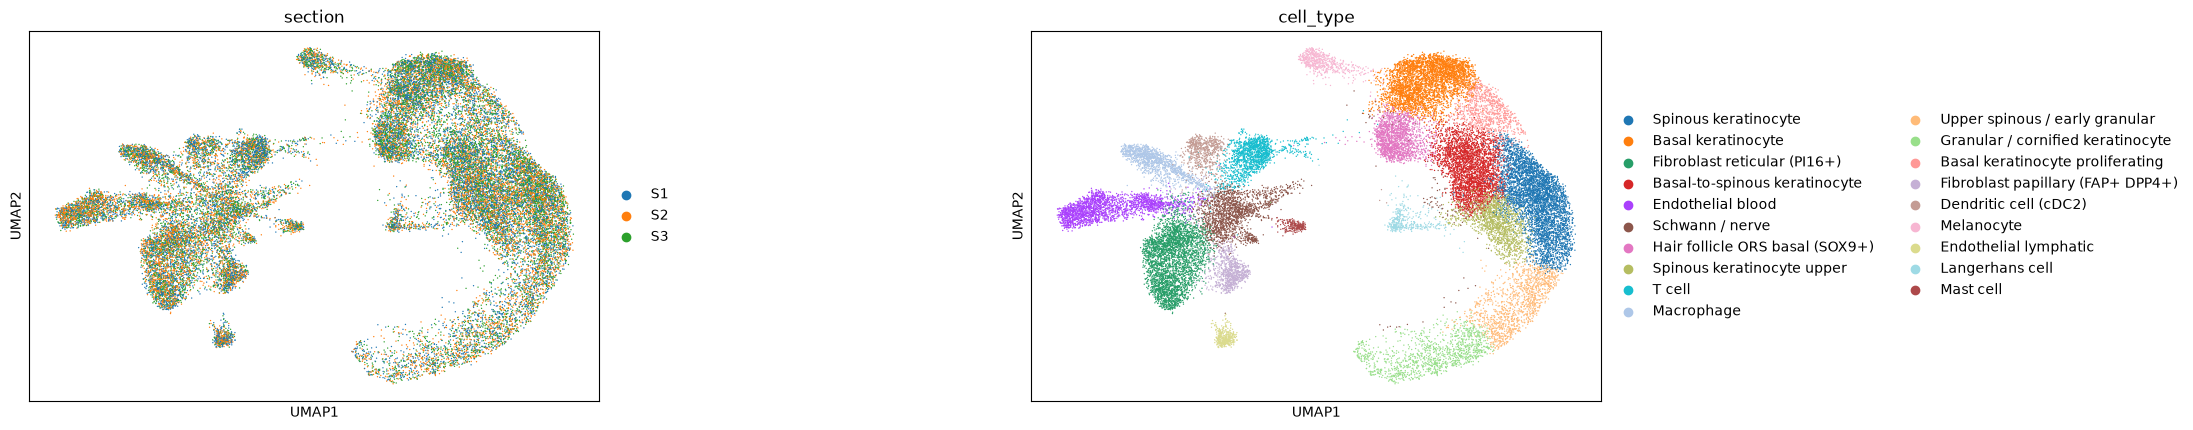

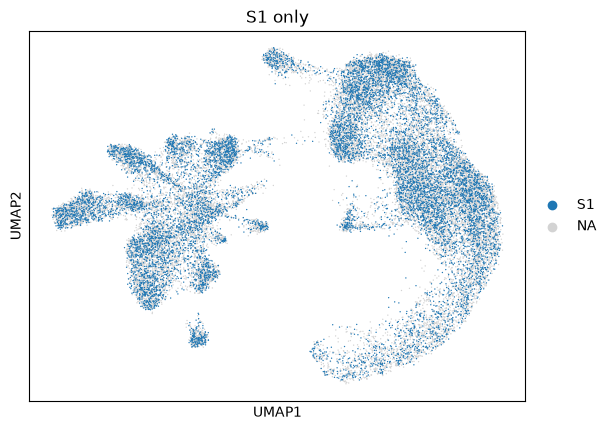

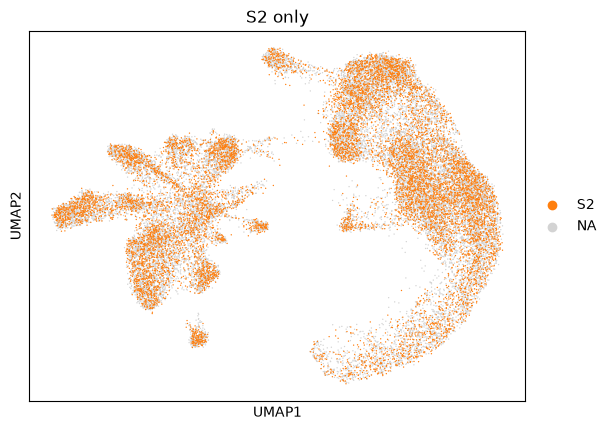

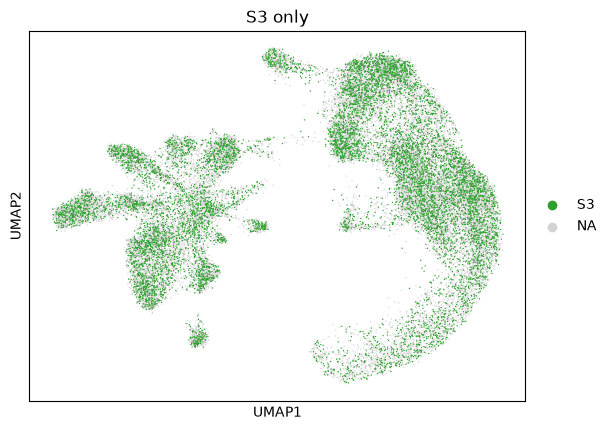

In [5]:
sc.pl.umap(adata, color=["section", "cell_type"], wspace=0.6)
sc.pl.umap(adata, color="section", groups=["S1"], title="S1 only")
sc.pl.umap(adata, color="section", groups=["S2"], title="S2 only")
sc.pl.umap(adata, color="section", groups=["S3"], title="S3 only")

In [6]:
prop = pd.crosstab(adata.obs["cell_type"], adata.obs["section"], normalize="columns").round(3)
prop

section,S1,S2,S3
cell_type,,,
Spinous keratinocyte,0.135,0.139,0.141
Basal keratinocyte,0.119,0.118,0.120
Fibroblast reticular (PI16+),0.104,0.103,0.105
Basal-to-spinous keratinocyte,0.098,0.101,0.101
Endothelial blood,0.071,0.073,0.066
Schwann / nerve,0.058,0.062,0.062
Hair follicle ORS basal (SOX9+),0.055,0.054,0.059
Spinous keratinocyte upper,0.048,0.047,0.054
T cell,0.054,0.047,0.043


<Axes: xlabel='cell_type', ylabel='fraction of section'>

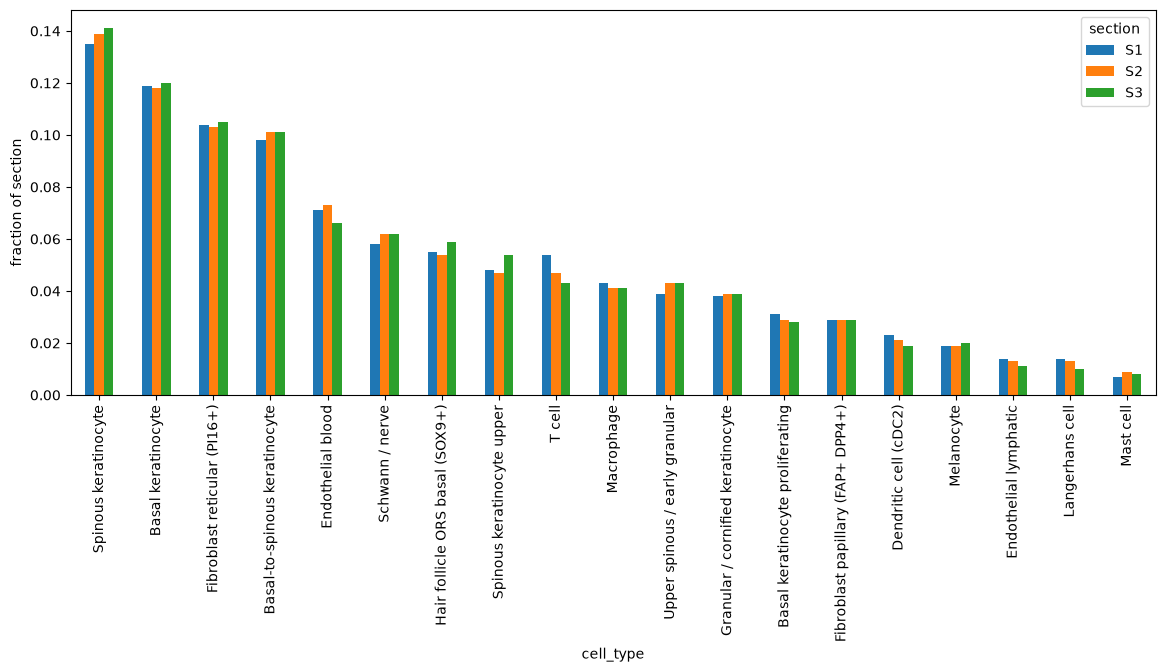

In [7]:
prop.plot(kind="bar", figsize=(14, 5), ylabel="fraction of section")

In [8]:
cl = pd.crosstab(adata.obs["leiden"], adata.obs["section"], normalize="index").round(2)
cl["max_share"] = cl[["S1", "S2", "S3"]].max(axis=1)
cl.sort_values("max_share", ascending=False)

section,S1,S2,S3,max_share
leiden,,,,
17,0.39,0.36,0.26,0.39
8,0.38,0.33,0.29,0.38
14,0.37,0.34,0.30,0.37
18,0.29,0.37,0.33,0.37
16,0.37,0.35,0.28,0.37
10,0.32,0.35,0.34,0.35
9,0.35,0.33,0.32,0.35
12,0.35,0.33,0.31,0.35
4,0.34,0.35,0.30,0.35


In [9]:
adata.obs.groupby("section")[["total_counts", "n_genes_by_counts", "cell_area"]].median()

,total_counts,n_genes_by_counts,cell_area
section,,,
S1,500.5,375.0,56.084065
S2,521.0,388.0,57.212971
S3,516.0,384.0,58.251565


In [10]:
adata.write(proc + "region1_niches.h5ad")